In [ ]:
!pip install torch torchio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.9/193.9 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 MB 23.7 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import nibabel as nib
import pickle
import os
from pathlib import Path
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
from tensorflow.keras.layers import (
    Input, Conv3D, BatchNormalization, Activation, MaxPool3D,
    GlobalAveragePooling3D, Dense, Dropout, Concatenate, Add
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")
INDEX_CSV = Path("/content/drive/MyDrive/Colab Notebooks/TTF1_CK7_data_index_ct_radiomics.csv")
MODEL_PATH = Path("/content/drive/MyDrive/Colab Notebook/model_ct_radiomics_RESNET.keras")
SCALER_PATH = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_scaler_RESNET.pkl")
MODEL_PATH_CT_ONLY = Path("/content/drive/MyDrive/Colab Notebooks/model_CT_ONLY_RESNET.keras")
MODEL_PATH_RAD_ONLY = Path("/content/drive/MyDrive/Colab Notebooks/model_RADIOMICS_ONLY.keras")
SCALER_PATH_RAD_ONLY = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_scaler_RAD_ONLY.pkl")

In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
import pandas as pd
import torch
import torchio as tio
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split

class BiomarkerDataset(Dataset):
    """
    Loads one 3D CT image and its corresponding labels [TTF1, CK7].
    """
    def __init__(self, manifest_df, transform=None):
        self.df = manifest_df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        sample_info = self.df.iloc[idx]
        ct_path = sample_info['ct_cropped_nifti_path']

        try:
            label_ttf1 = float(sample_info['TTF1'])
            label_ck7 = float(sample_info['CK7'])

            label_list = [label_ttf1, label_ck7]
            label_value = torch.tensor(label_list, dtype=torch.float32)

        except Exception as e:
            print(f"Error processing labels for code {sample_info.get('Code', 'N/A')}: {e}")
            label_value = torch.tensor([0.0, 0.0], dtype=torch.float32)

        subject = tio.Subject(
            ct_image=tio.ScalarImage(ct_path),
            label=label_value
        )

        ct_data = subject['ct_image'].data
        ct_min = ct_data.min().item()
        ct_max = ct_data.max().item()

        if ct_min == ct_max:
            print(f"[WARNING] Constant CT image detected: min=max={ct_min} | Code={sample_info['Code']} | Path={ct_path}")


        if self.transform:
            subject = self.transform(subject)

        ct_tensor = subject['ct_image'].data
        label_tensor = subject['label']

        return ct_tensor, label_tensor

TARGET_SHAPE = (128, 128, 128)

# base_intensity = tio.Compose([
#     tio.Clamp(out_min=-1000, out_max=400),
# ])

augment_transform = tio.Compose([
    # base_intensity,
    tio.CropOrPad(target_shape=TARGET_SHAPE, padding_mode=0),
    # tio.RandomFlip(axes=('LR',), p=0.5),
    # tio.RandomAffine(
    #     scales=(0.95, 1.05),
    #     degrees=(0, 0, 0, 0, -7, 7),
    #     p=0.75,
    # ),
    # tio.RandomNoise(p=0.25),
    # tio.RandomGamma(log_gamma=(-0.15, 0.15), p=0.25),
])

validation_transform = tio.Compose([
    # base_intensity,
    tio.CropOrPad(target_shape=TARGET_SHAPE, padding_mode=0),
])


def get_data_loaders(batch_size=4, num_workers=2, test_split_size=0.2, val_split_size=0.25):
    """
    Loads, merges, and performs a STRATIFIED split into
    Train, Validation, and Test sets based on TTF1/CK7 status.
    Returns three DataLoaders.
    """
    manifest_path = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
    labels_path = "/content/drive/MyDrive/Colab Notebooks/TTF1_CK7_data_index_ct_radiomics.csv"

    try:
        manifest_df = pd.read_csv(manifest_path)
        labels_df = pd.read_csv(labels_path)
    except FileNotFoundError as e:
        print(f"Error. No file found {e}")
        return None, None, None

    manifest_df['Code'] = manifest_df['Code'].astype(str).str.strip()
    labels_df['Code'] = labels_df['Code'].astype(str).str.strip()

    full_data_df = pd.merge(
        manifest_df[['Code', 'ct_cropped_nifti_path']],
        labels_df[['Code', 'TTF1', 'CK7']],
        on='Code',
        how='inner'
    )
    full_data_df = full_data_df[full_data_df['ct_cropped_nifti_path'].notna()]
    print(f"Found {len(full_data_df)} patients with paths and labels.")

    full_data_df['strat_key'] = 'TTF1_' + full_data_df['TTF1'].astype(str) + \
                                '_CK7_' + full_data_df['CK7'].astype(str)

    print("\n--- Group Distribution (Full Dataset) ---")
    print(full_data_df['strat_key'].value_counts())
    print("-------------------------------------------\n")

    try:
        train_val_df, test_df = train_test_split(
            full_data_df,
            test_size=test_split_size,
            random_state=42,
            stratify=full_data_df['strat_key']
        )
    except ValueError as e:
        print(f"ERROR: Could not perform stratified split. {e}")
        return None, None, None

    train_df, val_df = train_test_split(
        train_val_df,
        test_size=val_split_size,
        random_state=42,
        stratify=train_val_df['strat_key']
    )

    print("\n--- Train Set Distribution ---")
    print(train_df['strat_key'].value_counts().sort_index())

    print("\n--- Validation Set Distribution ---")
    print(val_df['strat_key'].value_counts().sort_index())

    print("\n--- Test Set Distribution ---")
    print(test_df['strat_key'].value_counts().sort_index())
    print("---------------------------------\n")

    train_dataset = BiomarkerDataset(manifest_df=train_df, transform=augment_transform)
    val_dataset = BiomarkerDataset(manifest_df=val_df, transform=validation_transform)
    test_dataset = BiomarkerDataset(manifest_df=test_df, transform=validation_transform)

    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers
    )

    val_loader = DataLoader(
        dataset=val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    print(f"DataLoaders created.")
    print(f"Train: {len(train_dataset)} cases")
    print(f"Validation: {len(val_dataset)} cases")
    print(f"Test: {len(test_dataset)} cases")

    return train_loader, val_loader, test_loader

In [ ]:
train_loader, val_loader, test_loader = get_data_loaders(batch_size=1, test_split_size=TEST_SPLIT, val_split_size=VAL_SPLIT)

Found 87 patients with paths and labels.

--- Group Distribution (Full Dataset) ---
strat_key
TTF1_1_CK7_0    31
TTF1_1_CK7_1    30
TTF1_0_CK7_0    14
TTF1_0_CK7_1    12
Name: count, dtype: int64
-------------------------------------------


--- Train Set Distribution ---
strat_key
TTF1_0_CK7_0    10
TTF1_0_CK7_1     9
TTF1_1_CK7_0    22
TTF1_1_CK7_1    21
Name: count, dtype: int64

--- Validation Set Distribution ---
strat_key
TTF1_0_CK7_0    2
TTF1_0_CK7_1    1
TTF1_1_CK7_0    4
TTF1_1_CK7_1    4
Name: count, dtype: int64

--- Test Set Distribution ---
strat_key
TTF1_0_CK7_0    2
TTF1_0_CK7_1    2
TTF1_1_CK7_0    5
TTF1_1_CK7_1    5
Name: count, dtype: int64
---------------------------------

DataLoaders created.
Train: 62 cases
Validation: 11 cases
Test: 14 cases


CT batch shape: torch.Size([1, 1, 128, 128, 128])
Labels batch: tensor([[1., 1.]])


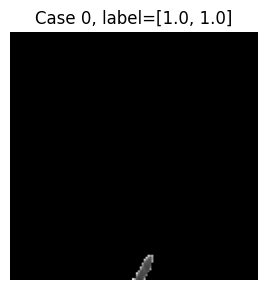

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ct_batch, label_batch = next(iter(train_loader))
print("CT batch shape:", ct_batch.shape)
print("Labels batch:", label_batch)

def show_ct_slice(ct_tensor, title=""):
    if ct_tensor.ndim == 4:
        ct_tensor = ct_tensor[0]

    ct_np = ct_tensor.numpy()
    d, h, w = ct_np.shape
    z = d // 2
    plt.imshow(ct_np[z, :, :], cmap="gray")
    plt.title(title)
    plt.axis("off")

N = min(8, ct_batch.shape[0])
plt.figure(figsize=(12, 3 * N))

for i in range(N):
    plt.subplot(1, N, i+1)
    show_ct_slice(ct_batch[i], title=f"Case {i}, label={label_batch[i].tolist()}")

plt.tight_layout()
plt.show()


In [ ]:
def load_ct_volume(ct_path: str, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized

In [ ]:
def load_radiomics_features(path: str):
    feats = {}
    if not os.path.exists(path):
        print(f"Path does not exists: {path}")
        return feats

    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

In [ ]:
def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        rad_path = str(RADIOMICS_DIR / f"{row['Code']}_radiomics.txt")

        if os.path.exists(rad_path):
            feats = load_radiomics_features(rad_path)
            feats["Code"] = row["Code"]
            rows.append(feats)
        else:
            print(f"No path: {rad_path}")

    r_df = pd.DataFrame(rows).fillna(0.0)
    return r_df

In [ ]:
print(f"Loading data index from: {INDEX_CSV}")
data_index = pd.read_csv(INDEX_CSV)
data_index["Code"] = data_index["Code"].astype(str)

y = data_index[["TTF1", "CK7"]].astype(np.float32).values
ct_paths = data_index["ct_path"].tolist()
codes = data_index["Code"].tolist()

print(f"Total number of patients found: {len(codes)}")

Loading data index from: /content/drive/MyDrive/Colab Notebooks/TTF1_CK7_data_index_ct_radiomics.csv
Total number of patients found: 87


In [ ]:
def resnet_block_3d(x, filters, strides=(1, 1, 1)):
    """Constructs a 3D residual block."""
    x_shortcut = x

    x = Conv3D(filters, (3, 3, 3), strides=strides, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv3D(filters, (3, 3, 3), padding="same")(x)
    x = BatchNormalization()(x)

    if strides != (1, 1, 1) or x_shortcut.shape[-1] != filters:
        x_shortcut = Conv3D(filters, (1, 1, 1), strides=strides, padding="same")(x_shortcut)
        x_shortcut = BatchNormalization()(x_shortcut)

    x = Add()([x, x_shortcut])
    x = Activation("relu")(x)
    return x

In [ ]:
def build_resnet_ct_only(input_shape):
    """Builds the CT-Only ResNet-3D model."""

    in_ct = Input(shape=input_shape, name="ct")

    x = Conv3D(16, (7, 7, 7), strides=(2, 2, 2), padding="same")(in_ct)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool3D((3, 3, 3), strides=(2, 2, 2), padding="same")(x)

    x = resnet_block_3d(x, 16)
    x = resnet_block_3d(x, 16)

    x = resnet_block_3d(x, 32, strides=(2, 2, 2))
    x = resnet_block_3d(x, 32)

    x = resnet_block_3d(x, 64, strides=(2, 2, 2))
    x = resnet_block_3d(x, 64)

    x = GlobalAveragePooling3D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.3)(x)

    out_ttf1 = Dense(1, activation="sigmoid", name="TTF1")(x)
    out_ck7 = Dense(1, activation="sigmoid", name="CK7")(x)

    model = Model(inputs=[in_ct],
                  outputs={"TTF1": out_ttf1, "CK7": out_ck7})

    model.compile(
        optimizer=Adam(LR),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
            "CK7": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
        }
    )
    return model

In [ ]:
def keras_adapter_generator(torch_loader):
    """
    converts a DataLoader into a compatibilae Keras generator (NumPy, channels-last).
    """
    while True:
        for ct_batch, label_batch in torch_loader:

            ct_numpy = ct_batch.numpy()
            label_numpy = label_batch.numpy()

            ct_numpy_channels_last = np.transpose(ct_numpy, (0, 2, 3, 4, 1))

            labels_dict = {
                'TTF1': label_numpy[:, 0],
                'CK7': label_numpy[:, 1]
            }

            yield ct_numpy_channels_last, labels_dict

In [ ]:
train_loader, val_loader, test_loader = get_data_loaders(batch_size=4)

Found 25 patients with paths and labels.

--- Group Distribution (Full Dataset) ---
strat_key
TTF1_1_CK7_0    8
TTF1_0_CK7_0    6
TTF1_0_CK7_1    6
TTF1_1_CK7_1    5
Name: count, dtype: int64
-------------------------------------------


--- Train Set Distribution ---
strat_key
TTF1_0_CK7_0    4
TTF1_0_CK7_1    4
TTF1_1_CK7_0    4
TTF1_1_CK7_1    3
Name: count, dtype: int64

--- Validation Set Distribution ---
strat_key
TTF1_0_CK7_0    1
TTF1_0_CK7_1    1
TTF1_1_CK7_0    2
TTF1_1_CK7_1    1
Name: count, dtype: int64

--- Test Set Distribution ---
strat_key
TTF1_0_CK7_0    1
TTF1_0_CK7_1    1
TTF1_1_CK7_0    2
TTF1_1_CK7_1    1
Name: count, dtype: int64
---------------------------------

DataLoaders created.
Train: 15 cases
Validation: 5 cases
Test: 5 cases


In [ ]:
EPOCHS = 100

print("\nBuilding CT-Only ResNet-3D model...")
keras_input_shape = TARGET_SHAPE + (1,)
model_ct_only = build_resnet_ct_only(input_shape=keras_input_shape)
model_ct_only.summary()

train_gen = keras_adapter_generator(train_loader)
val_gen = keras_adapter_generator(val_loader)
test_gen = keras_adapter_generator(test_loader)

steps_per_epoch = len(train_loader)
validation_steps = len(val_loader)
test_steps = len(test_loader)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH_CT_ONLY, monitor="val_loss", save_best_only=True)
]

print("\nStarting CT-Only model training...")
history_ct_only = model_ct_only.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps
)

print("\nCT-Only Training finished. Evaluating on test set:")
test_metrics_ct_only = model_ct_only.evaluate(
    test_gen,
    steps=test_steps,
    return_dict=True
)
print(test_metrics_ct_only)


Building CT-Only ResNet-3D model...


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_30 (Conv3D)  │ (None, 64, 64,    │      5,504 │ ct[0][0]          │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_30[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_26       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_2     │ (None, 32, 32,    │          0 │ activation_26[0]… │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_31 (Conv3D)  │ (None, 32, 32,    │      6,928 │ max_pooling3d_2[… │
│                     │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv3d_31[0][0]   │
│ (BatchNormalizatio… │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_27       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_32 (Conv3D)  │ (None, 32, 32,    │      6,928 │ activation_27[0]… │
│                     │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv3d_32[0][0]   │
│ (BatchNormalizatio… │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32, 16)           │            │ max_pooling3d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_28       │ (None, 32, 32,    │          0 │ add_12[0][0]      │
│ (Activation)        │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_33 (Conv3D)  │ (None, 32, 32,    │      6,928 │ activation_28[0]… │
│                     │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv3d_33[0][0]   │
│ (BatchNormalizatio… │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_29       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_34 (Conv3D)  │ (None, 32, 32,    │      6,928 │ activation_29[0]… │
│                     │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv3d_34[0][0] 

 Total params: 530,914 (2.03 MB)

 Trainable params: 529,794 (2.02 MB)

 Non-trainable params: 1,120 (4.38 KB)


Starting CT-Only model training...
Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 28s 153ms/step - CK7_AUC: 0.5781 - CK7_BinAcc: 0.6430 - CK7_loss: 0.6689 - TTF1_AUC: 0.4492 - TTF1_BinAcc: 0.5050 - TTF1_loss: 0.7419 - loss: 1.4108 - val_CK7_AUC: 0.5000 - val_CK7_BinAcc: 0.4545 - val_CK7_loss: 0.6962 - val_TTF1_AUC: 0.5000 - val_TTF1_BinAcc: 0.7273 - val_TTF1_loss: 0.6636 - val_loss: 1.3598 - learning_rate: 1.0000e-04
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - CK7_AUC: 0.5792 - CK7_BinAcc: 0.5040 - CK7_loss: 0.6877 - TTF1_AUC: 0.5040 - TTF1_BinAcc: 0.7223 - TTF1_loss: 0.6104 - loss: 1.2980 - val_CK7_AUC: 0.5000 - val_CK7_BinAcc: 0.4545 - val_CK7_loss: 0.6974 - val_TTF1_AUC: 0.5000 - val_TTF1_BinAcc: 0.7273 - val_TTF1_loss: 0.6538 - val_loss: 1.3513 - learning_rate: 1.0000e-04
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - CK7_AUC: 0.4766 - CK7_BinAcc: 0.4729 - CK7_loss: 0.7179 - TTF1_AUC: 0.4998 - TTF1_BinAcc: 0.6181 - TTF1_loss: 0.6997 - loss: 1.4176 - val_CK7_AUC: 0.5000 

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

def joint_confusion_matrix_4class(
    model,
    test_loader,
    keras_adapter_generator,
    test_steps,
    threshold=0.5
):
    test_gen = keras_adapter_generator(test_loader)

    y_true_joint = []
    y_pred_joint = []

    for _ in range(test_steps):
        x_batch, y_batch = next(test_gen)

        preds = model.predict(x_batch, verbose=0)

        t_true = y_batch["TTF1"].ravel().astype(int)
        c_true = y_batch["CK7"].ravel().astype(int)

        t_prob = preds["TTF1"].ravel()
        c_prob = preds["CK7"].ravel()

        t_pred = (t_prob >= threshold).astype(int)
        c_pred = (c_prob >= threshold).astype(int)

        for tt, cc, tp, cp in zip(t_true, c_true, t_pred, c_pred):
            if tt == 0 and cc == 0:
                y_true_joint.append(0)
            elif tt == 1 and cc == 0:
                y_true_joint.append(1)
            elif tt == 0 and cc == 1:
                y_true_joint.append(2)
            else:
                y_true_joint.append(3)


            if tp == 0 and cp == 0:
                y_pred_joint.append(0)
            elif tp == 1 and cp == 0:
                y_pred_joint.append(1)
            elif tp == 0 and cp == 1:
                y_pred_joint.append(2)
            else:
                y_pred_joint.append(3)

    y_true_joint = np.array(y_true_joint)
    y_pred_joint = np.array(y_pred_joint)

    labels = [0, 1, 2, 3]
    label_names = ["Niciunul", "Doar TTF1", "Doar CK7", "Ambele"]

    cm = confusion_matrix(y_true_joint, y_pred_joint, labels=labels)

    print("Matrice de confuzie 4-clase (TTF1+CK7):")
    print("Rows = True, Cols = Pred")
    print(label_names)
    print(cm)

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title("Confusion Matrix - Combinat TTF1/CK7")
    ax.set_xlabel("Predicție")
    ax.set_ylabel("Adevăr")

    ax.set_xticks(np.arange(len(label_names)))
    ax.set_yticks(np.arange(len(label_names)))
    ax.set_xticklabels(label_names, rotation=45, ha="right")
    ax.set_yticklabels(label_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")

    fig.tight_layout()
    plt.show()

    return cm, label_names


Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 2 0 0]
 [0 5 0 0]
 [0 2 0 0]
 [0 5 0 0]]


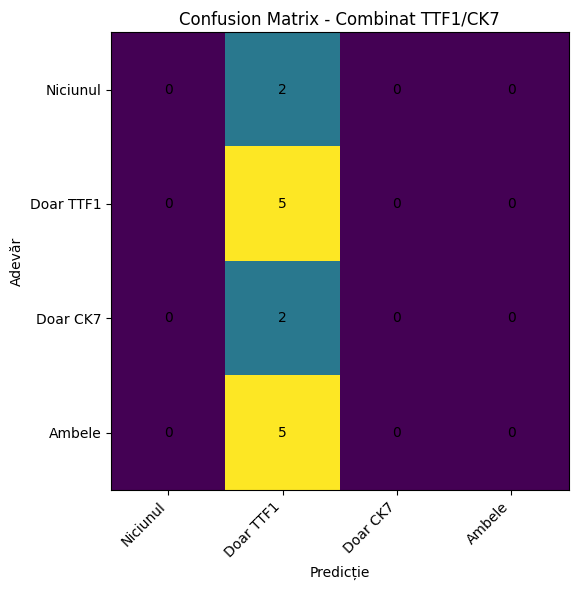

In [ ]:
cm_joint, joint_labels = joint_confusion_matrix_4class(
    model_ct_only,
    test_loader=test_loader,
    keras_adapter_generator=keras_adapter_generator,
    test_steps=test_steps,
    threshold=0.5
)


Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


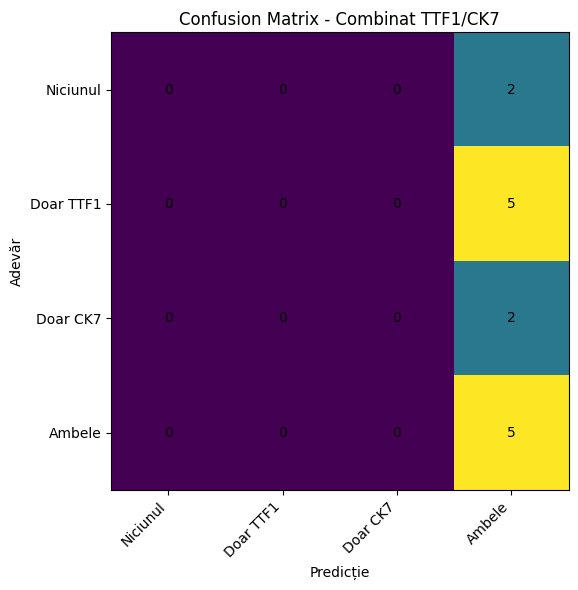

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


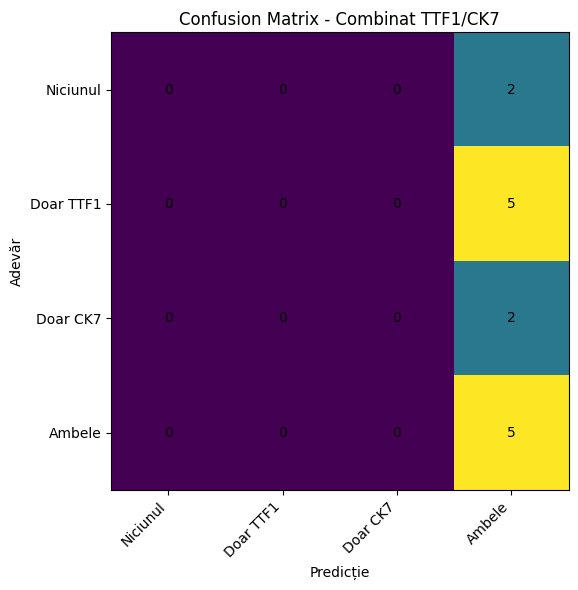

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


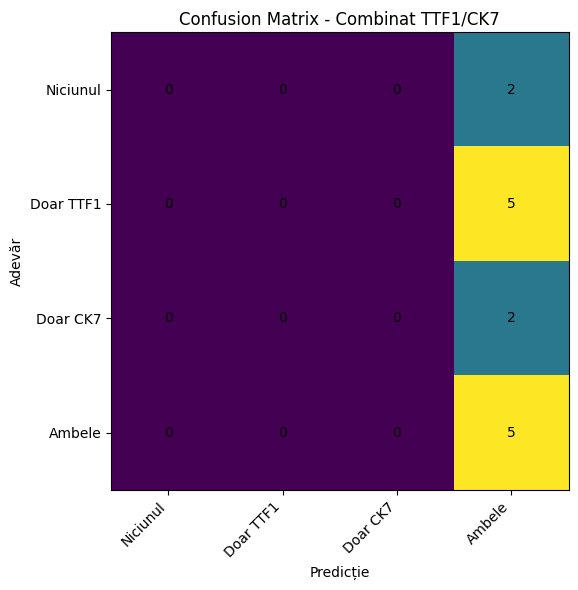

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


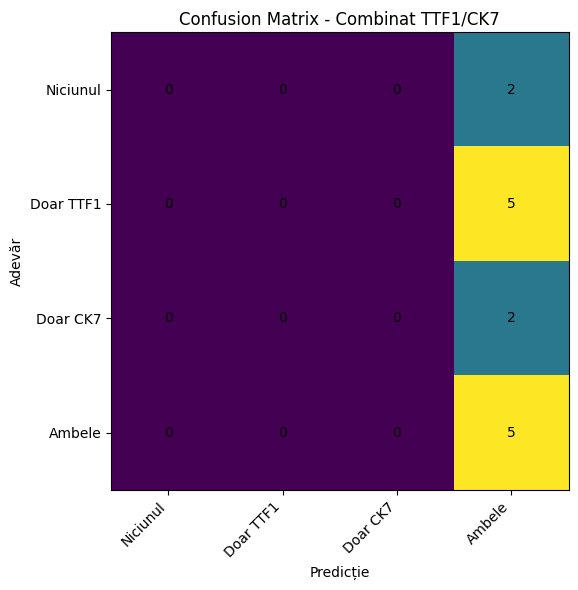

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 2 0 0]
 [0 5 0 0]
 [0 2 0 0]
 [0 5 0 0]]


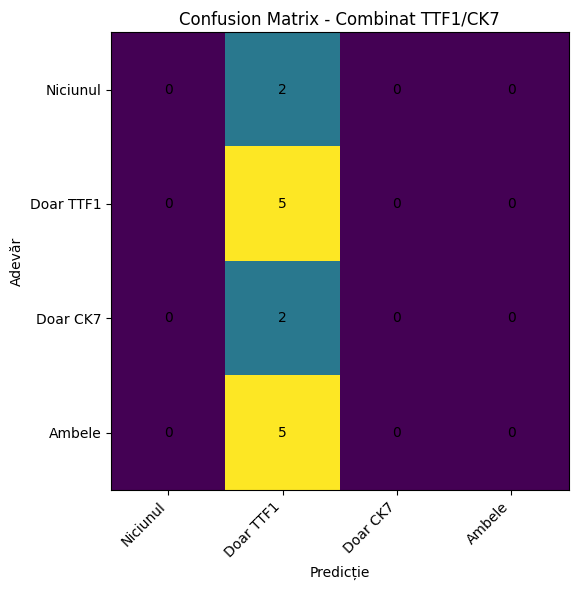

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 2 0 0]
 [0 5 0 0]
 [0 2 0 0]
 [0 5 0 0]]


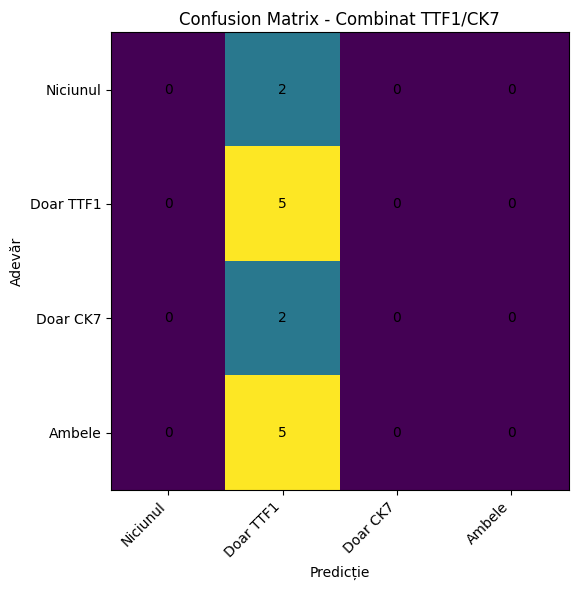

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


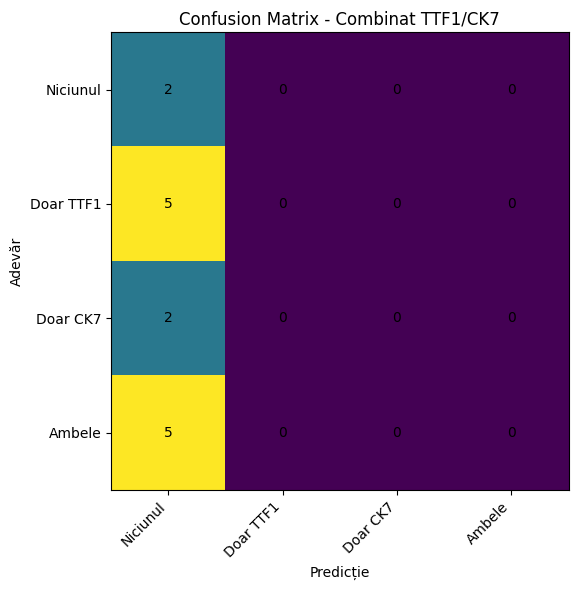

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


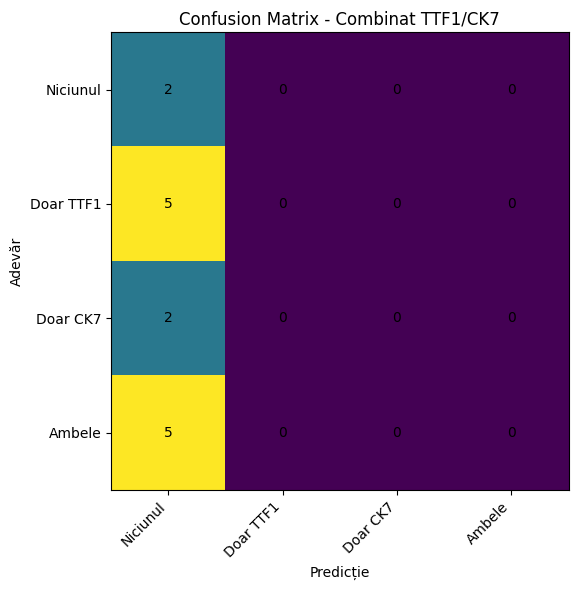

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


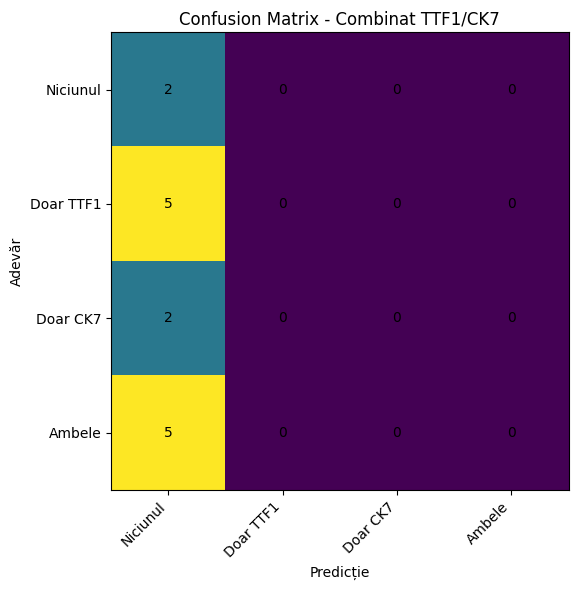

In [ ]:
for treshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
  cm_joint, joint_labels = joint_confusion_matrix_4class(
      model_ct_only,
      test_loader=test_loader,
      keras_adapter_generator=keras_adapter_generator,
      test_steps=test_steps,
      threshold=treshold
  )


CT batch shape: torch.Size([1, 1, 128, 128, 128])
Labels batch: tensor([[1., 1.]])


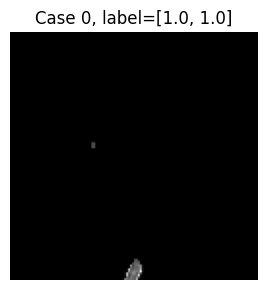

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ct_batch, label_batch = next(iter(train_loader))
print("CT batch shape:", ct_batch.shape)
print("Labels batch:", label_batch)
def show_ct_slice(ct_tensor, title=""):
    if ct_tensor.ndim == 4:
        ct_tensor = ct_tensor[0]

    ct_np = ct_tensor.numpy()
    d, h, w = ct_np.shape
    z = d // 2
    plt.imshow(ct_np[z, :, :], cmap="gray")
    plt.title(title)
    plt.axis("off")

N = min(8, ct_batch.shape[0])
plt.figure(figsize=(12, 3 * N))

for i in range(N):
    plt.subplot(1, N, i+1)
    show_ct_slice(ct_batch[i], title=f"Case {i}, label={label_batch[i].tolist()}")

plt.tight_layout()
plt.show()


In [ ]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import SpatialDropout3D
def build_light_ct_model(input_shape):
    reg_weight = 0.01

    in_ct = Input(shape=input_shape, name="ct")

    x = Conv3D(8, (3, 3, 3), padding="same", kernel_regularizer=l2(reg_weight))(in_ct)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool3D((2, 2, 2))(x)

    x = Conv3D(16, (3, 3, 3), padding="same", kernel_regularizer=l2(reg_weight))(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool3D((2, 2, 2))(x)

    x = SpatialDropout3D(0.2)(x)

    x = Conv3D(32, (3, 3, 3), padding="same", kernel_regularizer=l2(reg_weight))(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool3D((2, 2, 2))(x)

    x = SpatialDropout3D(0.3)(x)

    x = Conv3D(64, (3, 3, 3), padding="same", kernel_regularizer=l2(reg_weight))(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = GlobalAveragePooling3D()(x)

    x = Dense(32, activation="relu")(x)

    out_ttf1 = Dense(1, activation="sigmoid", name="TTF1")(x)
    out_ck7 = Dense(1, activation="sigmoid", name="CK7")(x)

    model = Model(inputs=[in_ct], outputs={"TTF1": out_ttf1, "CK7": out_ck7})

    opt = Adam(learning_rate=1e-4)

    model.compile(
        optimizer=opt,
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), "accuracy"],
            "CK7": [tf.keras.metrics.AUC(name="AUC"), "accuracy"],
        }
    )
    return model

In [ ]:
EPOCHS = 100

keras_input_shape = TARGET_SHAPE + (1,)
model = build_light_ct_model(input_shape=keras_input_shape)
model.summary()

train_gen = keras_adapter_generator(train_loader)
val_gen = keras_adapter_generator(val_loader)
test_gen = keras_adapter_generator(test_loader)

steps_per_epoch = len(train_loader)
validation_steps = len(val_loader)
test_steps = len(test_loader)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH_CT_ONLY, monitor="val_loss", save_best_only=True)
]

print("\nStarting CT-Only model training...")
history_ct_only = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps
)

print("\nCT-Only Training finished. Evaluating on test set:")
test_metrics_ct_only = model.evaluate(
    test_gen,
    steps=test_steps,
    return_dict=True
)
print(test_metrics_ct_only)

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_53 (Conv3D)  │ (None, 128, 128,  │        224 │ ct[0][0]          │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         32 │ conv3d_53[0][0]   │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_47       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_9     │ (None, 64, 64,    │          0 │ activation_47[0]… │
│ (MaxPooling3D)      │ 64, 8)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_54 (Conv3D)  │ (None, 64, 64,    │      3,472 │ max_pooling3d_9[… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_54[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_48       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_10    │ (None, 32, 32,    │          0 │ activation_48[0]… │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d_4 │ (None, 32, 32,    │          0 │ max_pooling3d_10… │
│ (SpatialDropout3D)  │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_55 (Conv3D)  │ (None, 32, 32,    │     13,856 │ spatial_dropout3… │
│                     │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv3d_55[0][0]   │
│ (BatchNormalizatio… │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_49       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_11    │ (None, 16, 16,    │          0 │ activation_49[0]… │
│ (MaxPooling3D)      │ 16, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d_5 │ (None, 16, 16,    │          0 │ max_pooling3d_11… │
│ (SpatialDropout3D)  │ 16, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_56 (Conv3D)  │ (None, 16, 16,    │     55,360 │ spatial_dropout3… │
│                     │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv3d_56[0][0] 

 Total params: 75,538 (295.07 KB)

 Trainable params: 75,298 (294.13 KB)

 Non-trainable params: 240 (960.00 B)


Starting CT-Only model training...
Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - CK7_AUC: 0.4110 - CK7_accuracy: 0.4279 - CK7_loss: 0.7040 - TTF1_AUC: 0.3753 - TTF1_accuracy: 0.7829 - TTF1_loss: 0.6016 - loss: 2.0568 - val_CK7_AUC: 0.2667 - val_CK7_accuracy: 0.5455 - val_CK7_loss: 0.6895 - val_TTF1_AUC: 0.5000 - val_TTF1_accuracy: 0.7273 - val_TTF1_loss: 0.6523 - val_loss: 2.0558 - learning_rate: 1.0000e-04
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - CK7_AUC: 0.4670 - CK7_accuracy: 0.5051 - CK7_loss: 0.6947 - TTF1_AUC: 0.4120 - TTF1_accuracy: 0.6870 - TTF1_loss: 0.6264 - loss: 2.0242 - val_CK7_AUC: 0.5000 - val_CK7_accuracy: 0.5455 - val_CK7_loss: 0.6896 - val_TTF1_AUC: 0.5000 - val_TTF1_accuracy: 0.7273 - val_TTF1_loss: 0.6356 - val_loss: 1.9962 - learning_rate: 1.0000e-04
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - CK7_AUC: 0.3920 - CK7_accuracy: 0.3706 - CK7_loss: 0.6959 - TTF1_AUC: 0.4350 - TTF1_accuracy: 0.6871 - TTF1_loss: 0.6283 - loss: 1.9852 - va

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


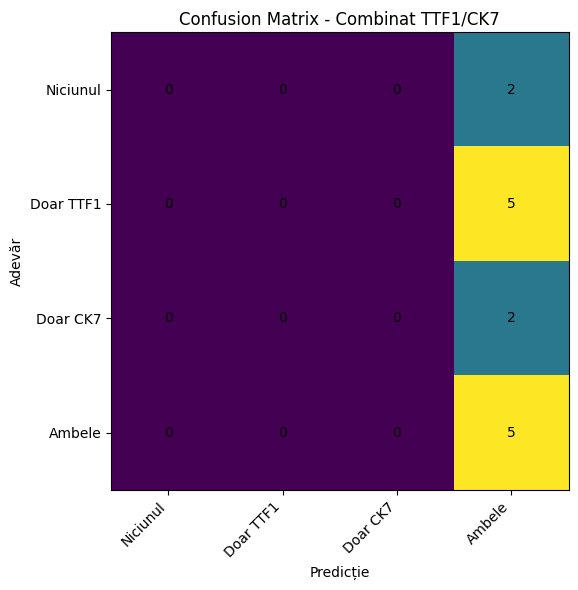

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


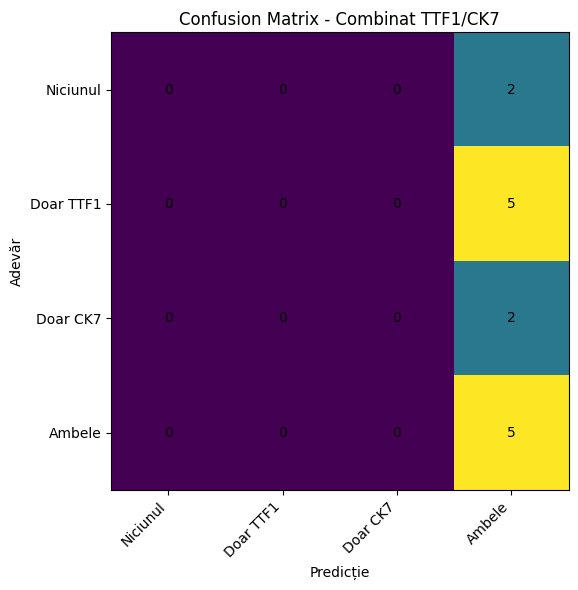

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


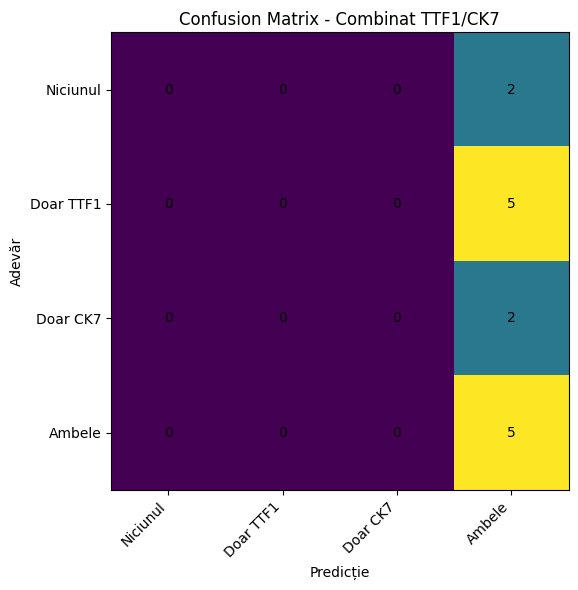

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 0 0 2]
 [0 0 0 5]
 [0 0 0 2]
 [0 0 0 5]]


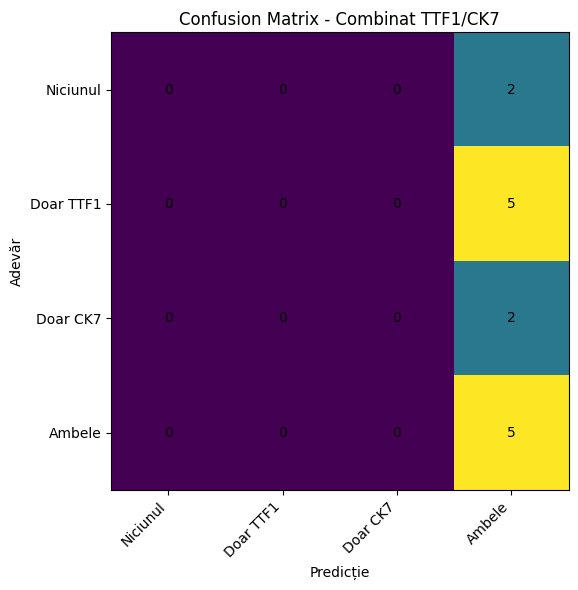

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 1 0 1]
 [0 5 0 0]
 [0 2 0 0]
 [0 5 0 0]]


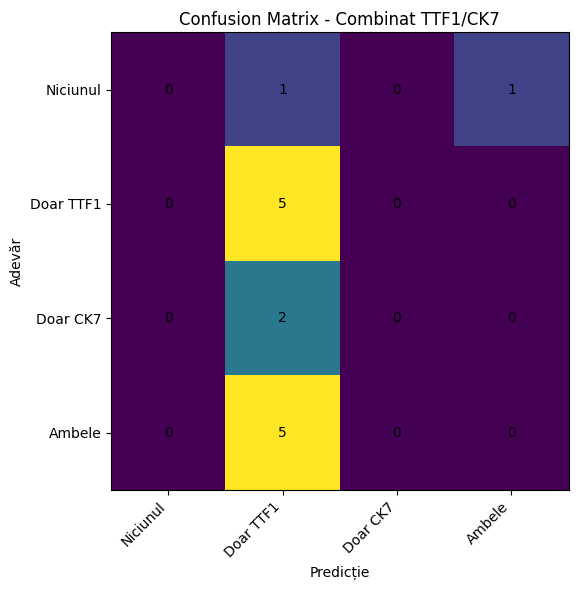

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[0 2 0 0]
 [0 5 0 0]
 [0 2 0 0]
 [0 5 0 0]]


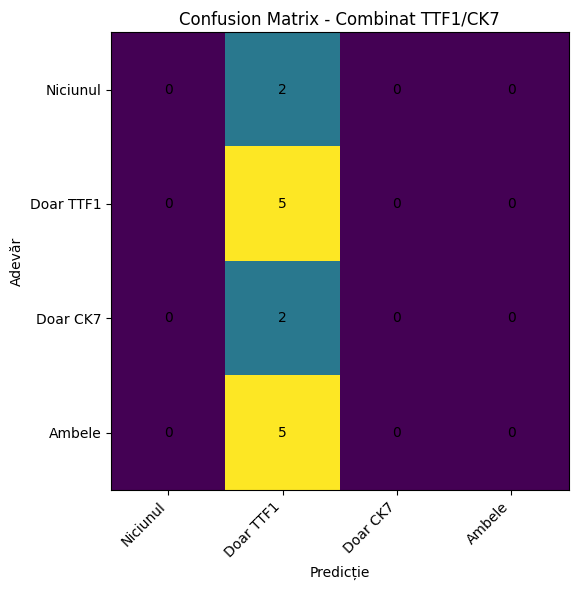

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


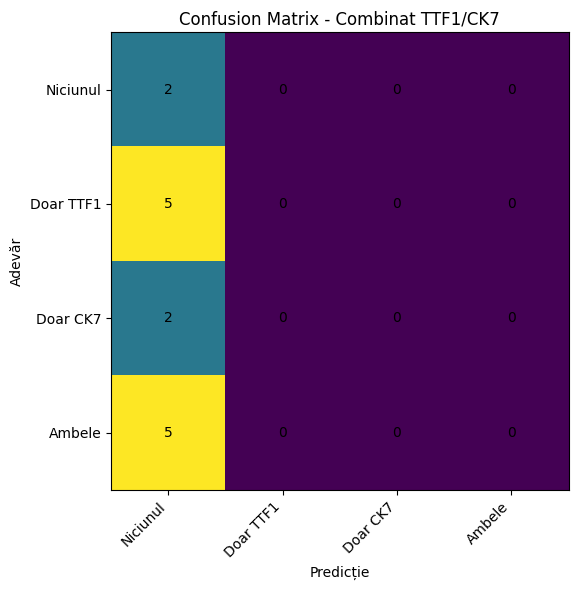

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


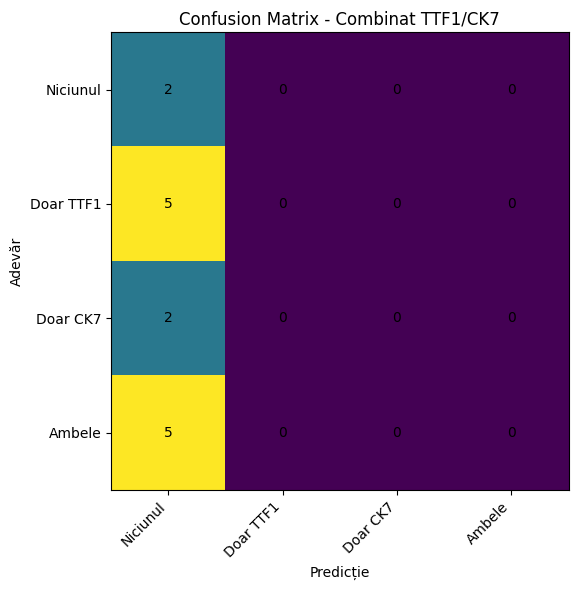

Matrice de confuzie 4-clase (TTF1+CK7):
Rows = True, Cols = Pred
['Niciunul', 'Doar TTF1', 'Doar CK7', 'Ambele']
[[2 0 0 0]
 [5 0 0 0]
 [2 0 0 0]
 [5 0 0 0]]


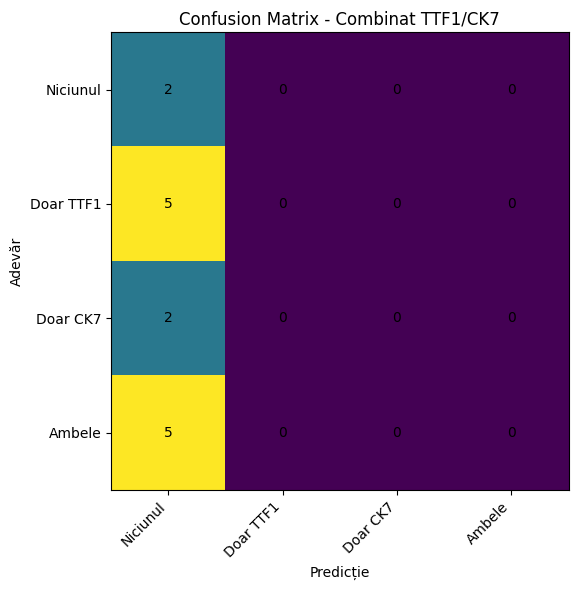

In [ ]:
for treshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
  cm_joint, joint_labels = joint_confusion_matrix_4class(
      model,
      test_loader=test_loader,
      keras_adapter_generator=keras_adapter_generator,
      test_steps=test_steps,
      threshold=treshold
  )

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

def plot_confusion_for_marker(y_true, y_prob, threshold=0.5, marker_name="TTF1"):
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(f"\n=== {marker_name} @ threshold={threshold:.3f} ===")
    print("Confusion matrix (rows=true, cols=pred):")
    print(cm)
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision : {prec:.3f}")
    print(f"Recall : {rec:.3f}")
    print(f"F1-score:  {f1:.3f}")

    fig, ax = plt.subplots(figsize=(4, 4))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{marker_name} Confusion Matrix")
    ax.set_xlabel("Predicție")
    ax.set_ylabel("Adevăr")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["0", "1"])
    ax.set_yticklabels(["0", "1"])

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")

    fig.tight_layout()
    plt.show()

    return cm, {"acc": acc, "prec": prec, "rec": rec, "f1": f1}


In [ ]:
import numpy as np

def collect_marker_probs(model, loader, keras_adapter_generator, steps):

    gen = keras_adapter_generator(loader)

    y_true_ttf1, y_prob_ttf1 = [], []
    y_true_ck7, y_prob_ck7 = [], []

    for _ in range(steps):
        x_batch, y_batch = next(gen)
        preds = model.predict(x_batch, verbose=0)

        y_true_ttf1.extend(y_batch["TTF1"].ravel())
        y_true_ck7.extend(y_batch["CK7"].ravel())

        y_prob_ttf1.extend(preds["TTF1"].ravel())
        y_prob_ck7.extend(preds["CK7"].ravel())

    y_true_ttf1 = np.array(y_true_ttf1).astype(int)
    y_prob_ttf1 = np.array(y_prob_ttf1)

    y_true_ck7 = np.array(y_true_ck7).astype(int)
    y_prob_ck7 = np.array(y_prob_ck7)

    return y_true_ttf1, y_prob_ttf1, y_true_ck7, y_prob_ck7


In [ ]:
val_steps = len(val_loader)
y_true_ttf1, y_prob_ttf1, y_true_ck7, y_prob_ck7 = collect_marker_probs(
    model,
    val_loader,
    keras_adapter_generator,
    val_steps
)



=== TTF1 @ threshold=0.100 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


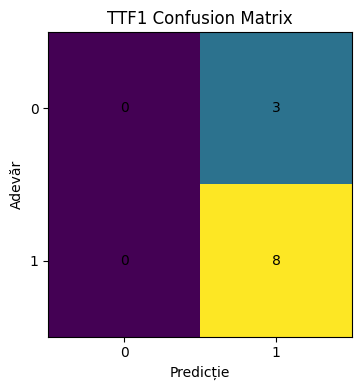


=== TTF1 @ threshold=0.200 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


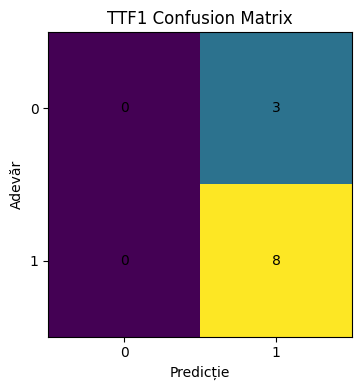


=== TTF1 @ threshold=0.300 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


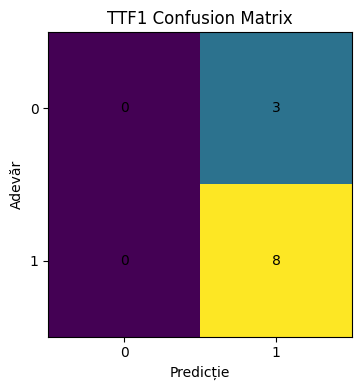


=== TTF1 @ threshold=0.400 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


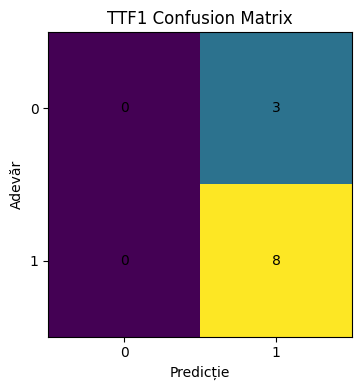


=== TTF1 @ threshold=0.500 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


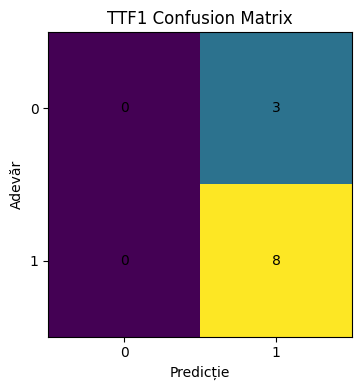


=== TTF1 @ threshold=0.600 ===
Confusion matrix (rows=true, cols=pred):
[[0 3]
 [0 8]]
Accuracy : 0.727
Precision: 0.727
Recall   : 1.000
F1-score : 0.842


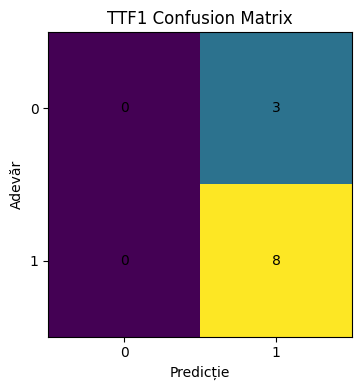


=== TTF1 @ threshold=0.700 ===
Confusion matrix (rows=true, cols=pred):
[[3 0]
 [8 0]]
Accuracy : 0.273
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


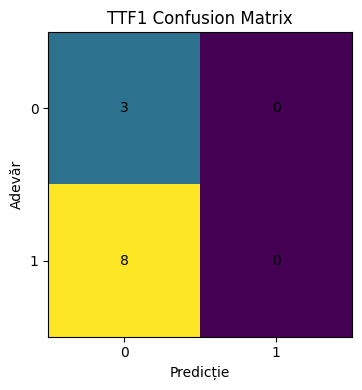


=== TTF1 @ threshold=0.800 ===
Confusion matrix (rows=true, cols=pred):
[[3 0]
 [8 0]]
Accuracy : 0.273
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


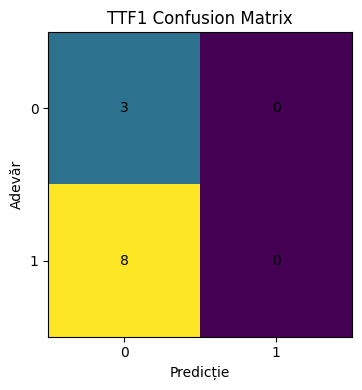


=== TTF1 @ threshold=0.900 ===
Confusion matrix (rows=true, cols=pred):
[[3 0]
 [8 0]]
Accuracy : 0.273
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


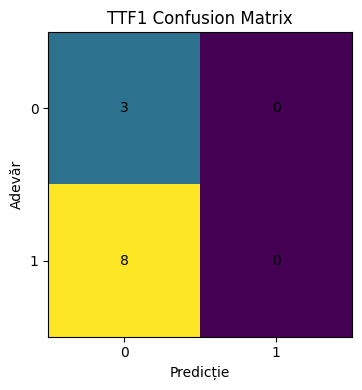

In [ ]:
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
  plot_confusion_for_marker(y_true_ttf1, y_prob_ttf1, threshold=th, marker_name="TTF1")




=== CK7 @ threshold=0.100 ===
Confusion matrix (rows=true, cols=pred):
[[0 6]
 [0 5]]
Accuracy : 0.455
Precision: 0.455
Recall   : 1.000
F1-score : 0.625


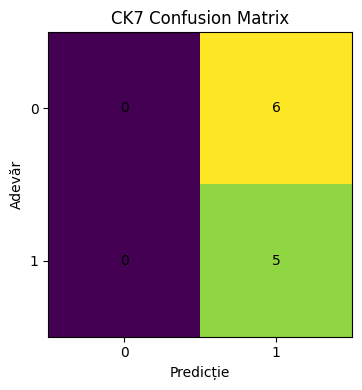


=== CK7 @ threshold=0.200 ===
Confusion matrix (rows=true, cols=pred):
[[0 6]
 [0 5]]
Accuracy : 0.455
Precision: 0.455
Recall   : 1.000
F1-score : 0.625


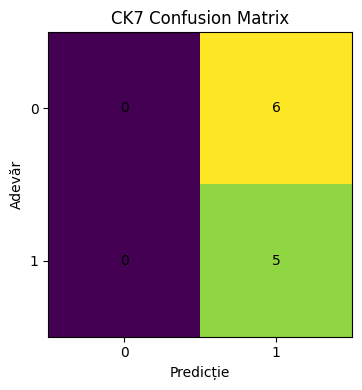


=== CK7 @ threshold=0.300 ===
Confusion matrix (rows=true, cols=pred):
[[0 6]
 [0 5]]
Accuracy : 0.455
Precision: 0.455
Recall   : 1.000
F1-score : 0.625


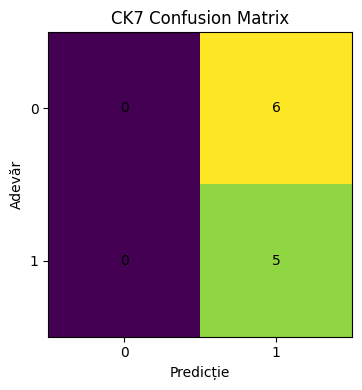


=== CK7 @ threshold=0.400 ===
Confusion matrix (rows=true, cols=pred):
[[0 6]
 [0 5]]
Accuracy : 0.455
Precision: 0.455
Recall   : 1.000
F1-score : 0.625


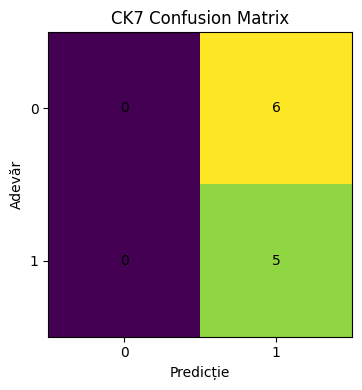


=== CK7 @ threshold=0.500 ===
Confusion matrix (rows=true, cols=pred):
[[6 0]
 [4 1]]
Accuracy : 0.636
Precision: 1.000
Recall   : 0.200
F1-score : 0.333


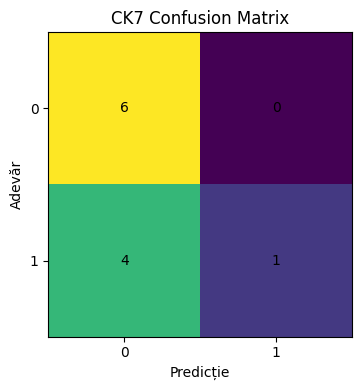


=== CK7 @ threshold=0.600 ===
Confusion matrix (rows=true, cols=pred):
[[6 0]
 [5 0]]
Accuracy : 0.545
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


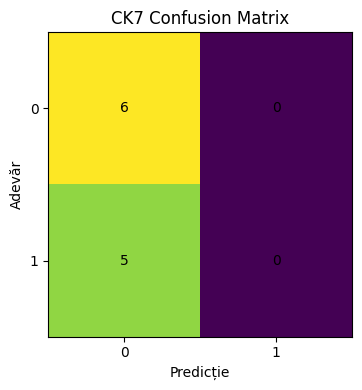


=== CK7 @ threshold=0.700 ===
Confusion matrix (rows=true, cols=pred):
[[6 0]
 [5 0]]
Accuracy : 0.545
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


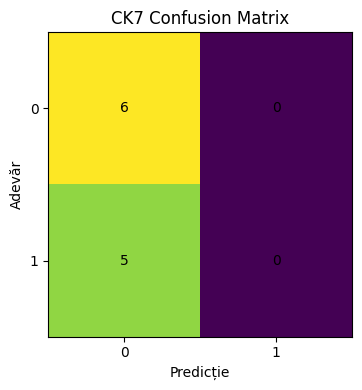


=== CK7 @ threshold=0.800 ===
Confusion matrix (rows=true, cols=pred):
[[6 0]
 [5 0]]
Accuracy : 0.545
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


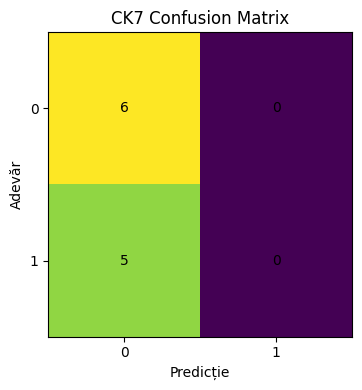


=== CK7 @ threshold=0.900 ===
Confusion matrix (rows=true, cols=pred):
[[6 0]
 [5 0]]
Accuracy : 0.545
Precision: 0.000
Recall   : 0.000
F1-score : 0.000


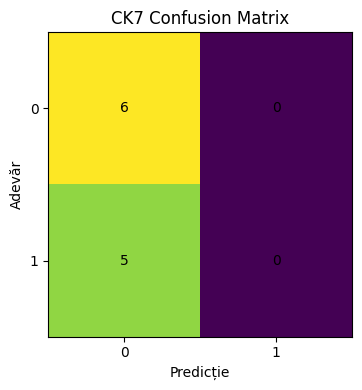

In [ ]:
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
  plot_confusion_for_marker(y_true_ck7,  y_prob_ck7,  threshold=th, marker_name="CK7")

In [ ]:
train_df = train_loader.dataset.df
val_df   = val_loader.dataset.df
test_df  = test_loader.dataset.df

print("=== TRAIN ===")
print(train_df[['Code', 'TTF1', 'CK7']])

print("\n=== VAL ===")
print(val_df[['Code', 'TTF1', 'CK7']])

print("\n=== TEST ===")
print(test_df[['Code', 'TTF1', 'CK7']])

=== TRAIN ===
      Code  TTF1  CK7
82  101011     1    1
86  453011     1    1
64   81111     0    1
0     2011     1    0
20   28111     1    1
..     ...   ...  ...
40   54011     0    0
77   95111     1    0
56   71111     1    1
9    12111     1    0
30   40011     0    1

[62 rows x 3 columns]

=== VAL ===
      Code  TTF1  CK7
83  102111     1    0
61   77011     1    0
16   23111     1    1
1     3111     1    1
46   61011     1    1
62   79111     1    0
27   35111     0    0
14   19111     1    1
21   29111     0    0
17   24111     0    1
51   66011     1    0

=== TEST ===
      Code  TTF1  CK7
31   42111     0    0
75   93111     0    1
71   89011     1    0
28   36111     1    1
25   33111     1    1
49   64011     1    1
18   25111     0    0
11   15011     1    1
63   80111     1    0
34   45111     0    1
85  104011     1    0
67   84011     1    0
36   48011     1    0
41   55011     1    1
